<a href="https://colab.research.google.com/github/slimani-meriem/w2vec/blob/main/02_piste_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys

REPO_URL = "https://github.com/slimani-meriem/w2vec.git"
REPO_DIR = "/content/w2vec"

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull

sys.path.insert(0, f"{REPO_DIR}/src")

from data import *
from w2v import train_from_corpus
from eval_w2v import get_embeddings, evaluate, evaluate_runs

Mounted at /content/drive
Cloning into '/content/w2vec'...
remote: Enumerating objects: 95, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (72/72), done.
remote: Total 95 (delta 42), reused 66 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (95/95), 8.63 MiB | 17.67 MiB/s, done.
Resolving deltas: 100% (42/42), done.


In [2]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

False 


In [ ]:
!ls -lh /content/drive/MyDrive/tp-ml-w2vec

total 133M
-rw------- 1 root root 133M Nov  1 08:53 dataset.json


# **Premières évaluations et pistes d'amélioration des performances**
Ce notebook a pour objectif de réaliser les premiers entraînements, de comparer les embeddings implémentés from scratch avec ceux de Gensim, et d'explorer différentes pistes pour améliorer les performances des embeddings Word2Vec.

In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import filter_rare_words, load_dataset
from w2v import w2v, save_embeddings
from eval_w2v import get_embeddings, evaluate

# --- Entrées (dépôt) ---
CORPUS   = f"{REPO_DIR}/data/Le_comte_de_Monte_Cristo.tok"
SIM_FILE = f"{REPO_DIR}/data/Le_comte_de_Monte_Cristo.100.sim.txt"

# --- Sorties (Drive, persistantes) ---
OUT_DIR      = "/content/drive/MyDrive/tp-ml-w2vec"
FILTERED     = f"{OUT_DIR}/filtered_text.txt"
DATASET_PATH = f"{OUT_DIR}/dataset.json"
RESULTS_CSV  = f"{OUT_DIR}/results.csv"
LOSSES_JSON  = f"{OUT_DIR}/losses.json"

# --- Hyperparamètres de l'énoncé ---
N = 100        # dimension des embeddings
ETA = 0.1      # taux d'apprentissage
E = 5          # nombre d'itérations
MINC = 5       # occurrences minimales
N_RUNS = 10

In [3]:
_, valid_words = filter_rare_words(CORPUS, FILTERED, minc=MINC)
dataset = load_dataset(DATASET_PATH)

print(f"Vocabulaire : {len(valid_words)} mots")
print(f"Dataset : {len(dataset)} exemples")

Vocabulaire : 3156 mots
Dataset : 876832 exemples


## **Partie 1 : Premiers entraînements**
### **1.1 Entraînement d'embeddings w2v**

In [ ]:
# test d'exécution
t0 = time.time()
W_test, losses_test = w2v(dataset, valid_words, n=N, max_iter=1, eta=ETA, seed=0)
dt = time.time() - t0
print(f"1 itération : {dt:.0f} s")
print(f"Estimation pour {N_RUNS} runs x {E} itérations : {dt * E * N_RUNS / 3600:.1f} h")

Itération 1/1 - perte moyenne : 3.0534
1 itération : 70 s
Estimation pour 10 runs x 5 itérations : 1.0 h


In [ ]:
rows = []
all_losses = {}
all_loss_details = {}

for seed in range(N_RUNS):
    out = f"{OUT_DIR}/embeddings_piste_1_seed{seed}.txt"
    t0 = time.time()

    details = {}

    W, losses = w2v(
        dataset, valid_words, n=N, max_iter=E, eta=ETA,
        seed=seed, loss_details=details
    )

    save_embeddings(W, valid_words, out)
    res = evaluate(get_embeddings(out), SIM_FILE)

    time_s = round(time.time() - t0)

    rows.append({
        "seed": seed,
        "rate": res["rate"],
        "correct": res["correct"],
        "total": res["total"],
        "oov": res["oov"],
        "final_loss": losses[-1],
        "final_loss_pos": details["pos"][-1],
        "final_loss_neg": details["neg"][-1],
        "time_s": time_s
    })

    all_losses[str(seed)] = losses
    all_loss_details[str(seed)] = details

    # Affichage des losses à chaque itération
    print(f"\n========== RUN seed={seed} ==========")
    print(f"{'Iteration':<12} {'Positive loss':<18} {'Negative loss':<18} {'Total loss':<18}")

    for i, (pos, neg, total) in enumerate(
        zip(details["pos"], details["neg"], losses), start=1
    ):
        print(f"{i:<12} {pos:<18.6f} {neg:<18.6f} {total:<18.6f}")

    print(
        f"\nTaux = {res['rate']:.3f} | "
        f"Perte finale = {losses[-1]:.3f} | Temps = {time_s} s"
    )

# Sauvegarde des résultats
pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)

json.dump(all_losses, open(LOSSES_JSON, "w"))
json.dump(
    all_loss_details,
    open(LOSSES_JSON.replace(".json", "_details.json"), "w")
)

Itération 1/5 - perte moyenne : 3.0534
Itération 2/5 - perte moyenne : 2.8751
Itération 3/5 - perte moyenne : 2.8358
Itération 4/5 - perte moyenne : 2.8190
Itération 5/5 - perte moyenne : 2.8111

========== RUN seed=0 ==========
Iteration    Positive loss      Negative loss      Total loss        
1            2.106477           0.946955           3.053432          
2            1.971796           0.903263           2.875059          
3            1.938054           0.897734           2.835788          
4            1.923234           0.895789           2.819024          
5            1.915784           0.895363           2.811147          

Taux = 0.760 | Perte finale = 2.811 | Temps = 368 s
Itération 1/5 - perte moyenne : 3.0540
Itération 2/5 - perte moyenne : 2.8746
Itération 3/5 - perte moyenne : 2.8364
Itération 4/5 - perte moyenne : 2.8194
Itération 5/5 - perte moyenne : 2.8109

========== RUN seed=1 ==========
Iteration    Positive loss      Negative loss      Total loss        

In [ ]:
losses_finales = [
    2.811147, 2.810932, 2.810415, 2.811383, 2.811247,
    2.810862, 2.811587, 2.811214, 2.810918, 2.809832
]

print(f"Loss: {np.mean(losses_finales):.4} ± {np.std(losses_finales):.4}")

taux = [0.760, 0.780, 0.760, 0.690, 0.760,
        0.740, 0.780, 0.700, 0.750, 0.690]

print(f"Taux : {np.mean(taux):.4f} ± {np.std(taux):.4}")

Loss: 2.811 ± 0.0004832
Taux : 0.7410 ± 0.0333


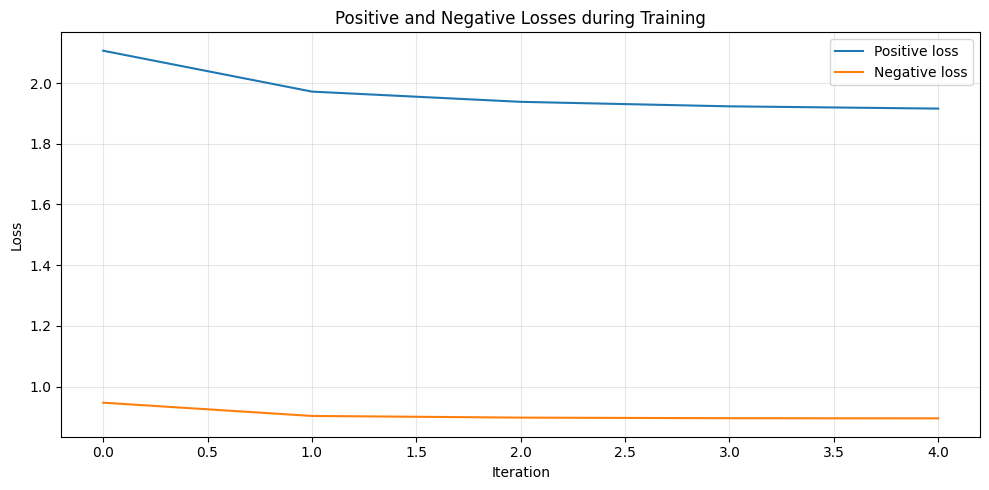

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(details["pos"], label="Positive loss")
plt.plot(details["neg"], label="Negative loss")

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Positive and Negative Losses during Training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
!cp /content/w2vec/data/filtered_text.txt /content/drive/MyDrive/tp-ml-w2vec//

### **1.2 Entraîner les embeddings Gensim**
Nous allons directement utiliser le texte prétraité : les mots dont la fréquence d'apparition est inférieure à minc ont déjà été éliminés, et tous les mots ont été convertis en minuscules. C'est pourquoi nous fixerons min_count à 1 pour Gensim, au lieu de 5 comme pour Word2Vec, afin de ne pas supprimer davantage de mots.

In [6]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 26.5 MB/s  0:00:01


In [7]:
from gensim.models import Word2Vec

WINDOW = 5      # pour Gensim, la taille de la fenête = contexte gauche + mot cible + contexte droit = 2*L + 1 = 5
K_NEG  = 10      # même nombre de négatifs k que dans le dataset utilisé dans w2v
MIN_COUNT = 1   # pour garder tous les mots et pas en supprimer davantage

# pour rappel : FILTERED chemin vers le fichier contenant le texte filtré (élimination des mots < minc)
with open(FILTERED, encoding="utf-8") as f:
    sentences = [line.split() for line in f if line.strip()]

print(len(sentences), "phrases")
print(sentences[:2])

9512 phrases
[['<s>', '<s>', 'le', 'février', '1815', ',', 'la', 'de', 'notre', '-', 'dame', 'de', 'la', 'garde', 'le', 'trois', '-', 'le', 'pharaon', ',', 'venant', 'de', 'smyrne', ',', 'et', 'naples', '.', '</s>', '</s>'], ['<s>', '<s>', 'comme', 'd’', 'habitude', ',', 'un', 'pilote', 'partit', 'aussitôt', 'du', 'port', ',', 'le', 'château', 'd’', 'if', ',', 'et', 'alla', 'aborder', 'le', 'navire', 'entre', 'le', 'cap', 'de', 'et', 'l’', 'île', 'de', '.', '</s>', '</s>']]


In [8]:
rows_gs = []
for seed in range(N_RUNS):
    out = f"{OUT_DIR}/gensim_embeddings_seed{seed}.txt"
    t0 = time.time()

    model = Word2Vec(
        sentences=sentences,
        vector_size=N,        # même dimension que pour w2v
        window=WINDOW,
        min_count=MIN_COUNT,
        sg=1,                 # skip-gram
        negative=K_NEG,       # negative sampling
        alpha=ETA,            # taux d'apprentissage initial
        epochs=E,
        seed=seed,
        workers=1,
    )

    # On enregistre les embeddings appris dans le même ordre que pour les embeddings w2v
    # model.wv étant la liste des embeddings appris (un dictionnaire)
    words = [w for w in valid_words if w in model.wv.key_to_index]
    W_gs = np.vstack([model.wv[w] for w in words])

    save_embeddings(W_gs, words, out)
    res = evaluate(get_embeddings(out), SIM_FILE)

    rows_gs.append({"seed": seed, "rate": res["rate"], "correct": res["correct"],
                    "total": res["total"], "oov": res["oov"],
                    "n_words": len(words), "time_s": round(time.time() - t0)})
    print(f"[gensim] seed {seed} : taux = {res['rate']:.3f} | oov = {res['oov']} "
          f"| {rows_gs[-1]['time_s']} s")

df_gs = pd.DataFrame(rows_gs)
df_gs.to_csv(f"{OUT_DIR}/gensim_results.csv", index=False)
print(f"\nBaseline Gensim : taux moyen = {df_gs['rate'].mean():.3f} ± {df_gs['rate'].std():.3f}")

[gensim] seed 0 : taux = 0.840 | oov = 0 | 10 s
[gensim] seed 1 : taux = 0.820 | oov = 0 | 9 s
[gensim] seed 2 : taux = 0.890 | oov = 0 | 8 s
[gensim] seed 3 : taux = 0.830 | oov = 0 | 9 s
[gensim] seed 4 : taux = 0.870 | oov = 0 | 8 s
[gensim] seed 5 : taux = 0.810 | oov = 0 | 9 s
[gensim] seed 6 : taux = 0.840 | oov = 0 | 10 s
[gensim] seed 7 : taux = 0.810 | oov = 0 | 8 s
[gensim] seed 8 : taux = 0.830 | oov = 0 | 10 s
[gensim] seed 9 : taux = 0.830 | oov = 0 | 8 s

Baseline Gensim : taux moyen = 0.837 ± 0.025


## **Partie 2 : Exploration de pistes d'amélioration**

### **Piste 1 : Méthode d'initialisation de W**

In [ ]:
rows = []
all_losses = {}
all_loss_details = {}

for seed in range(N_RUNS):
    out = f"{OUT_DIR}/embeddings_piste_1_seed{seed}.txt"
    t0 = time.time()

    details = {}

    W, losses = w2v(
        dataset, valid_words, n=N, max_iter=E, eta=ETA,
        seed=seed, loss_details=details
    )

    save_embeddings(W, valid_words, out)
    res = evaluate(get_embeddings(out), SIM_FILE)

    time_s = round(time.time() - t0)

    rows.append({
        "seed": seed,
        "rate": res["rate"],
        "correct": res["correct"],
        "total": res["total"],
        "oov": res["oov"],
        "final_loss": losses[-1],
        "final_loss_pos": details["pos"][-1],
        "final_loss_neg": details["neg"][-1],
        "time_s": time_s
    })

    all_losses[str(seed)] = losses
    all_loss_details[str(seed)] = details

    # Affichage des losses à chaque itération
    print(f"\n========== RUN seed={seed} ==========")
    print(f"{'Iteration':<12} {'Positive loss':<18} {'Negative loss':<18} {'Total loss':<18}")

    for i, (pos, neg, total) in enumerate(
        zip(details["pos"], details["neg"], losses), start=1
    ):
        print(f"{i:<12} {pos:<18.6f} {neg:<18.6f} {total:<18.6f}")

    print(
        f"\nTaux = {res['rate']:.3f} | "
        f"Perte finale = {losses[-1]:.3f} | Temps = {time_s} s"
    )

# Sauvegarde des résultats
pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)

json.dump(all_losses, open(LOSSES_JSON, "w"))
json.dump(
    all_loss_details,
    open(LOSSES_JSON.replace(".json", "_details.json"), "w")
)

Itération 1/5 - perte moyenne : 2.9471
Itération 2/5 - perte moyenne : 2.8205
Itération 3/5 - perte moyenne : 2.8073
Itération 4/5 - perte moyenne : 2.8009
Itération 5/5 - perte moyenne : 2.7971

========== RUN seed=0 ==========
Iteration    Positive loss      Negative loss      Total loss        
1            1.960576           0.986573           2.947149          
2            1.933888           0.886638           2.820525          
3            1.919277           0.888059           2.807337          
4            1.911277           0.889631           2.800908          
5            1.905936           0.891125           2.797061          

Taux = 0.770 | Perte finale = 2.797 | Temps = 385 s
Itération 1/5 - perte moyenne : 2.9475
Itération 2/5 - perte moyenne : 2.8200
Itération 3/5 - perte moyenne : 2.8067
Itération 4/5 - perte moyenne : 2.8008
Itération 5/5 - perte moyenne : 2.7968

========== RUN seed=1 ==========
Iteration    Positive loss      Negative loss      Total loss        

In [ ]:
final_losses = [row["final_loss"] for row in rows]
rates = [row["rate"] for row in rows]

print(f"Losses : {np.mean(final_losses):.6f} ± {np.std(final_losses, ddof=1):.6f}")

print(f"Taux : {np.mean(rates)*100:.2f}% ± {np.std(rates, ddof=1)*100:.2f}%")

Losses : 2.796921 ± 0.000460
Taux : 75.50% ± 1.72%


In [ ]:
import shutil, glob, os

DRIVE_DIR = "/content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1"   # dossier de destination
os.makedirs(DRIVE_DIR, exist_ok=True)

for f in glob.glob(f"{OUT_DIR}/embeddings_piste_1_seed*.txt"):
    shutil.copy(f, DRIVE_DIR)
    print("copié :", f)

copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed0.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed1.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed2.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed3.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed4.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed5.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed6.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed7.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed8.txt
copié : /content/drive/MyDrive/tp-ml-w2vec/embeddings_piste_1_seed9.txt


### **Piste 2 : Nombre d'itération E**
Pour des raisons de reproductibilité, nous allons explorer cette piste sur un seul run avec seed = 0

In [4]:
seed = 0
out = f"{OUT_DIR}/embeddings_details_run_seed{seed}.txt"

def evaluation_function(W):
    save_embeddings(W, valid_words, out)
    res = evaluate(get_embeddings(out), SIM_FILE)
    return res["rate"]

In [6]:
t0 = time.time()
details = {}

E_NEW = 3 * E  # Augmenter le nombre d'itérations pour observer le plateau
W, losses, scores = w2v(
    dataset, valid_words,
    n=N,
    max_iter=E_NEW,
    eta=ETA,
    seed=seed,
    loss_details=details,
    eval_fn=evaluation_function
)


# Sauvegarde finale des embeddings
save_embeddings(W, valid_words, out)
res = evaluate(get_embeddings(out), SIM_FILE)

time_s = round(time.time() - t0)


# Résultats de l'évaluation finale
row = {
    "seed": seed,
    "rate": res["rate"],
    "correct": res["correct"],
    "total": res["total"],
    "oov": res["oov"],
    "final_loss": losses[-1],
    "final_loss_pos": details["pos"][-1],
    "final_loss_neg": details["neg"][-1],
    "time_s": time_s
}


# Sauvegarde des résultats
pd.DataFrame([row]).to_csv(RESULTS_CSV, index=False)

json.dump({"0": losses}, open(LOSSES_JSON, "w"))

json.dump(
    {"0": details, "scores": scores},
    open(LOSSES_JSON.replace(".json", "_details.json"), "w")
)


# Affichage des résultats
print(
    f"seed {seed} : taux = {res['rate']:.3f} | "
    f"perte finale = {losses[-1]:.3f} "
    f"(pos = {details['pos'][-1]:.3f}, "
    f"neg = {details['neg'][-1]:.3f}) "
    f"scores = {scores}"
    f"| {time_s} s"
)

Itération 1/15 - perte moyenne : 2.9471
Itération 2/15 - perte moyenne : 2.8205
Itération 3/15 - perte moyenne : 2.8073
Itération 4/15 - perte moyenne : 2.8009
Itération 5/15 - perte moyenne : 2.7971
Itération 6/15 - perte moyenne : 2.7946
Itération 7/15 - perte moyenne : 2.7942
Itération 8/15 - perte moyenne : 2.7945
Itération 9/15 - perte moyenne : 2.7951
Itération 10/15 - perte moyenne : 2.7963
Itération 11/15 - perte moyenne : 2.7969
Itération 12/15 - perte moyenne : 2.7976
Itération 13/15 - perte moyenne : 2.7982
Itération 14/15 - perte moyenne : 2.7986
Itération 15/15 - perte moyenne : 2.7995
seed 0 : taux = 0.820 | perte finale = 2.799 (pos = 1.902, neg = 0.897) scores = [0.75, 0.73, 0.75, 0.77, 0.77, 0.79, 0.81, 0.76, 0.76, 0.82, 0.78, 0.7, 0.76, 0.75, 0.82]| 947 s


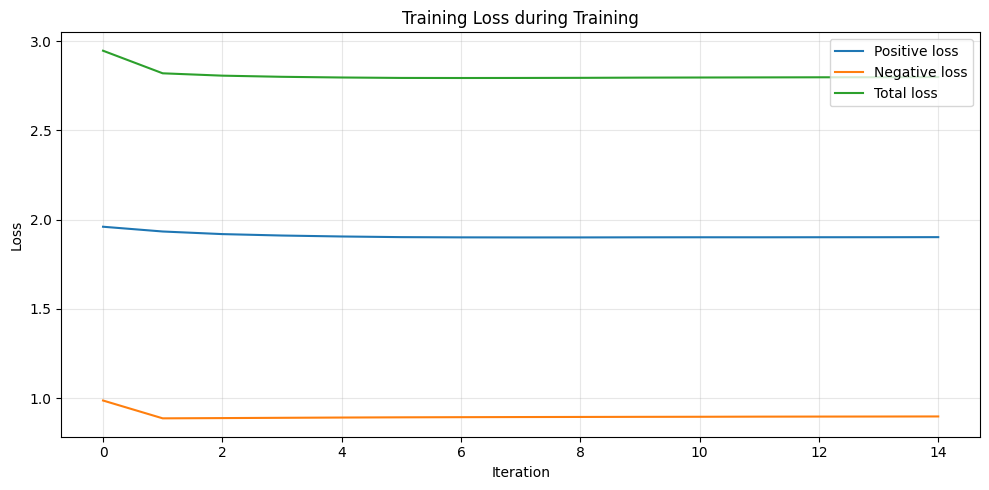

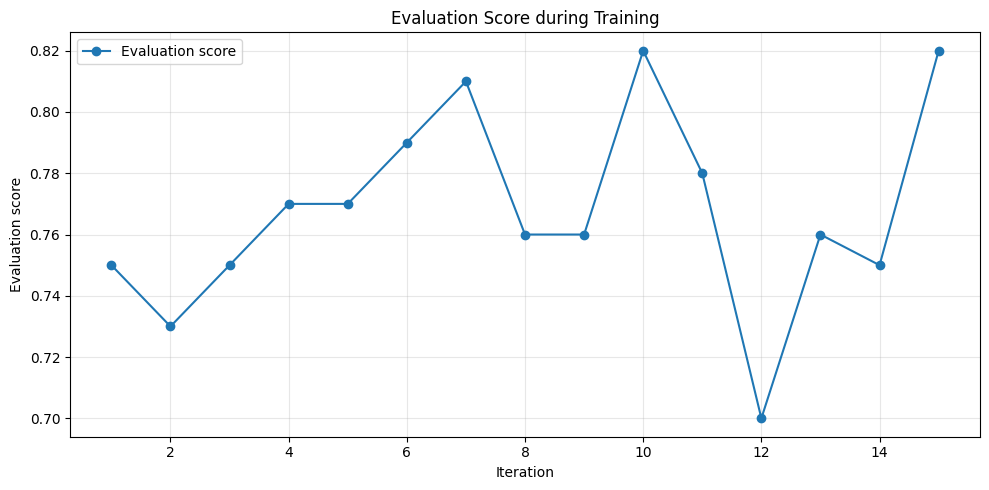

In [7]:

plt.figure(figsize=(10, 5))

plt.plot(details["pos"], label="Positive loss")
plt.plot(details["neg"], label="Negative loss")
plt.plot(losses, label="Total loss")

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss during Training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Evolution du score d'évaluation
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(scores) + 1),
    scores,
    marker="o",
    label="Evaluation score"
)

plt.xlabel("Iteration")
plt.ylabel("Evaluation score")
plt.title("Evaluation Score during Training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### **Piste 3 : Taux d'apprentissage eta**
Implémentation d'une linear decay du learning rate comme le fait l'algorithme de gensim.

In [6]:
t0 = time.time()
details = {}

ETA_MIN = 1e-4
W, losses, scores = w2v(
    dataset, valid_words,
    n=N,
    max_iter=E,
    eta=ETA,
    seed=seed,
    loss_details=details,
    eval_fn=evaluation_function,
    eta_min=ETA_MIN
)


# Sauvegarde finale des embeddings
save_embeddings(W, valid_words, out)
res = evaluate(get_embeddings(out), SIM_FILE)

time_s = round(time.time() - t0)


# Résultats de l'évaluation finale
row = {
    "seed": seed,
    "rate": res["rate"],
    "correct": res["correct"],
    "total": res["total"],
    "oov": res["oov"],
    "final_loss": losses[-1],
    "final_loss_pos": details["pos"][-1],
    "final_loss_neg": details["neg"][-1],
    "time_s": time_s
}


# Sauvegarde des résultats
pd.DataFrame([row]).to_csv(RESULTS_CSV, index=False)

json.dump({"0": losses}, open(LOSSES_JSON, "w"))

json.dump(
    {"0": details, "scores": scores},
    open(LOSSES_JSON.replace(".json", "_details.json"), "w")
)


# Affichage des résultats
print(
    f"seed {seed} : taux = {res['rate']:.3f} | "
    f"perte finale = {losses[-1]:.3f} "
    f"(pos = {details['pos'][-1]:.3f}, "
    f"neg = {details['neg'][-1]:.3f}) "
    f"scores = {scores}"
    f"| {time_s} s"
)

Itération 1/5 - perte moyenne : 2.9277
Itération 2/5 - perte moyenne : 2.7367
Itération 3/5 - perte moyenne : 2.6442
Itération 4/5 - perte moyenne : 2.5547
Itération 5/5 - perte moyenne : 2.4677
seed 0 : taux = 0.800 | perte finale = 2.468 (pos = 1.664, neg = 0.804) scores = [0.77, 0.8, 0.77, 0.82, 0.8]| 324 s


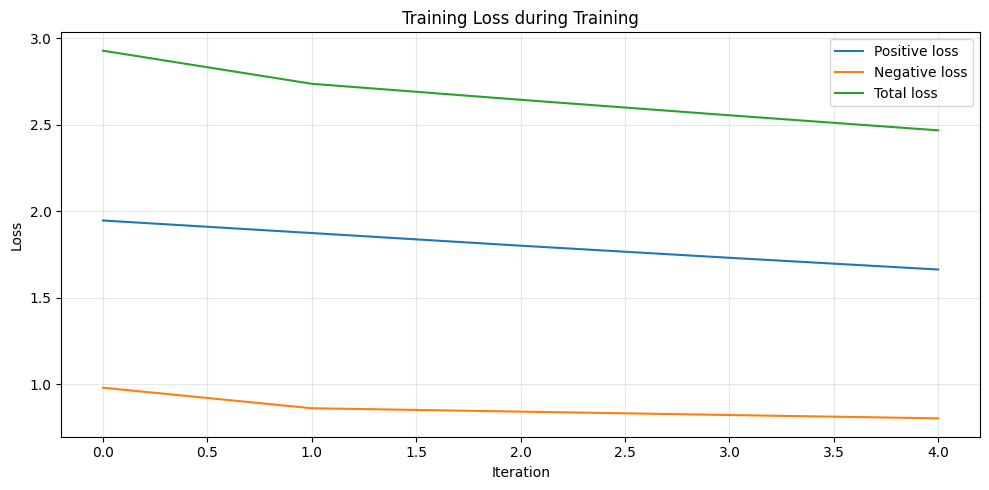

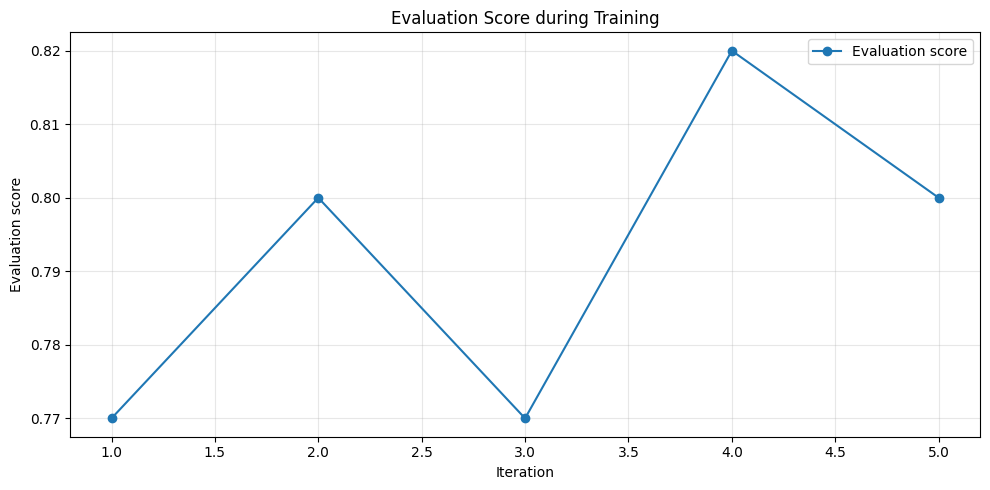

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(details["pos"], label="Positive loss")
plt.plot(details["neg"], label="Negative loss")
plt.plot(losses, label="Total loss")

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss during Training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Evolution du score d'évaluation
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(scores) + 1),
    scores,
    marker="o",
    label="Evaluation score"
)

plt.xlabel("Iteration")
plt.ylabel("Evaluation score")
plt.title("Evaluation Score during Training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

[constant] seed 0 : moy5 = 0.754 | std5 = 0.015 | final = 0.77 | 249 s
[constant] seed 1 : moy5 = 0.760 | std5 = 0.030 | final = 0.75 | 245 s
[constant] seed 2 : moy5 = 0.780 | std5 = 0.015 | final = 0.77 | 242 s
[constant] seed 3 : moy5 = 0.770 | std5 = 0.032 | final = 0.75 | 244 s
[constant] seed 4 : moy5 = 0.748 | std5 = 0.023 | final = 0.78 | 244 s
[constant] seed 5 : moy5 = 0.768 | std5 = 0.010 | final = 0.75 | 239 s
[constant] seed 6 : moy5 = 0.774 | std5 = 0.022 | final = 0.76 | 241 s
[constant] seed 7 : moy5 = 0.754 | std5 = 0.022 | final = 0.74 | 240 s
[constant] seed 8 : moy5 = 0.750 | std5 = 0.021 | final = 0.76 | 241 s
[constant] seed 9 : moy5 = 0.722 | std5 = 0.017 | final = 0.72 | 243 s
[lineaire] seed 0 : moy5 = 0.792 | std5 = 0.019 | final = 0.80 | 242 s
[lineaire] seed 1 : moy5 = 0.808 | std5 = 0.016 | final = 0.81 | 242 s
[lineaire] seed 2 : moy5 = 0.790 | std5 = 0.015 | final = 0.79 | 242 s
[lineaire] seed 3 : moy5 = 0.788 | std5 = 0.030 | final = 0.81 | 243 s
[linea

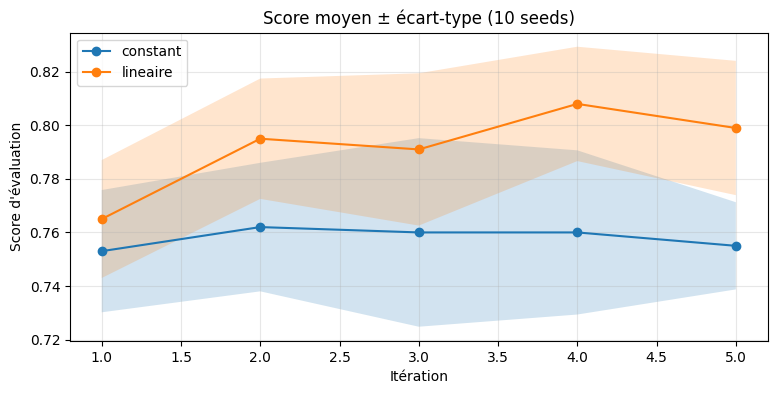

In [5]:
N_SEEDS = 10
E_TEST  = 5
TMP     = f"{OUT_DIR}/tmp_eval.txt"

def make_eval_fn(scores):
    """eval_fn(W) -> score ; ajoute aussi le score à la liste `scores` (1 valeur par itération)."""
    def eval_fn(W):
        save_embeddings(W, valid_words, TMP)
        s = evaluate(get_embeddings(TMP), SIM_FILE)["rate"]
        scores.append(s)
        return s
    return eval_fn

configs = {
    "constant": dict(eta=ETA, eta_min=None),     # eta constant (référence)
    "lineaire": dict(eta=ETA, eta_min=1e-4),     # décroissance linéaire ETA -> 1e-4
    # "lineaire x2": dict(eta=2 * ETA, eta_min=1e-4),   # seulement si l'init centrée de W est bien active
}

rows, curves = [], {name: [] for name in configs}

for name, cfg in configs.items():
    for seed in range(N_SEEDS):
        scores, d = [], {}
        t0 = time.time()
        res = w2v(dataset, valid_words, n=N, max_iter=E_TEST, seed=seed,
                  eval_fn=make_eval_fn(scores), loss_details=d, verbose=False, **cfg)
        losses = res[1]

        if np.isnan(losses[-1]):
            print(f"[{name}] seed {seed} : DIVERGENCE (nan), baisser eta")
        last = np.array(scores[-5:])
        rows.append({"config": name, "seed": seed,
                     "mean_last5": last.mean(), "std_last5": last.std(),
                     "final": scores[-1], "loss": losses[-1], "pos": d["pos"][-1]})
        curves[name].append(scores)
        print(f"[{name}] seed {seed} : moy5 = {last.mean():.3f} | std5 = {last.std():.3f} "
              f"| final = {scores[-1]:.2f} | {time.time() - t0:.0f} s")

df = pd.DataFrame(rows)
df.to_csv(f"{OUT_DIR}/piste3_runs.csv", index=False)

summary = df.groupby("config").agg(
    mean_last5=("mean_last5", "mean"),            # niveau moyen en fin d'entraînement
    std_within=("std_last5", "mean"),             # instabilité d'un run (entre itérations)
    std_between_seeds=("mean_last5", "std"),      # variabilité entre seeds
    final=("final", "mean"),
    pos=("pos", "mean"),
)
print(summary.round(3))

# Différence appariée (mêmes seeds) : linéaire - constant
piv = df.pivot(index="seed", columns="config", values="mean_last5")
diff = piv["lineaire"] - piv["constant"]
print(f"\nDiff. moyenne (lineaire - constant) sur {N_SEEDS} seeds : "
      f"{diff.mean():+.3f} ± {diff.std():.3f}")

# Courbes : score moyen ± écart-type entre seeds, par itération
plt.figure(figsize=(9, 4))
for name, runs in curves.items():
    arr = np.array(runs)                          # (N_SEEDS, E_TEST)
    m, s = arr.mean(axis=0), arr.std(axis=0)
    x = np.arange(1, arr.shape[1] + 1)
    plt.plot(x, m, marker="o", label=name)
    plt.fill_between(x, m - s, m + s, alpha=0.2)
plt.xlabel("Itération"); plt.ylabel("Score d'évaluation")
plt.title(f"Score moyen ± écart-type ({N_SEEDS} seeds)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## **Combien de places les mots non informatifs prennent dans notre dataset ?**

876832 exemples | 8768320 négatifs au total (10.0 par exemple)


,cible,%cible,positif,%positif,négatif,%négatif,rang cible,rang positif,rang négatif
mot,,,,,,,,,
de,26572,3.030,26572,3.030,117688,1.342,4,4,4
la,16328,1.862,16328,1.862,85586,0.976,8,8,8
le,17264,1.969,17264,1.969,88701,1.012,6,6,6
et,17132,1.954,17132,1.954,88347,1.008,7,7,7
à,15932,1.817,15932,1.817,84193,0.960,9,9,9
un,10188,1.162,10188,1.162,61862,0.706,15,15,15
une,6748,0.770,6748,0.770,46019,0.525,22,22,22
des,4064,0.463,4064,0.463,31874,0.364,42,42,42
en,8120,0.926,8120,0.926,53018,0.605,18,18,18


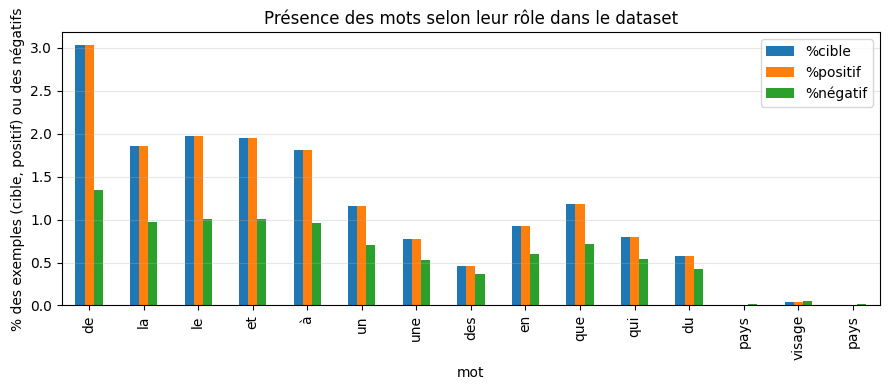

In [6]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

WORDS = ["de", "la", "le", "et", "à", "un", "une", "des", "en", "que", "qui", "du", "pays", "visage", "pays"]

n_ex = len(dataset)

count_target = Counter(t for t, p, negs in dataset)
count_pos    = Counter(p for t, p, negs in dataset)
count_neg    = Counter(w for t, p, negs in dataset for w in negs)
n_neg_total = sum(count_neg.values())

# rang de chaque mot
def ranks(counter):
    return {w: i + 1 for i, (w, _) in enumerate(counter.most_common())}
rank_t, rank_p, rank_n = ranks(count_target), ranks(count_pos), ranks(count_neg)

rows = []
for w in WORDS:
    ct, cp, cn = count_target[w], count_pos[w], count_neg[w]
    rows.append({
        "mot": w,
        "cible": ct,       "%cible": 100 * ct / n_ex,
        "positif": cp,     "%positif": 100 * cp / n_ex,
        "négatif": cn,     "%négatif": 100 * cn / n_neg_total,
        "rang cible": rank_t.get(w), "rang positif": rank_p.get(w), "rang négatif": rank_n.get(w),
    })

df_words = pd.DataFrame(rows).set_index("mot")
print(f"{n_ex} exemples | {n_neg_total} négatifs au total ({n_neg_total / n_ex} par exemple)")
display(df_words.round(3))

role = df_words[["%cible", "%positif", "%négatif"]]
role.plot(kind="bar", figsize=(9, 4))
plt.ylabel("% des exemples (cible, positif) ou des négatifs")
plt.title("Présence des mots selon leur rôle dans le dataset")
plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()